# Iris Dataset: Complete Exploratory Data Analysis

## Objective
Inspect the genuine UCI Iris data, compare four flower measurements across the three species, assess data quality, and visualize distributions and relationships.

**Source:** [UCI Iris (dataset 53)](https://archive.ics.uci.edu/dataset/53/iris), originally collected by R. A. Fisher. Measurements are centimeters.

## Load and inspect
The reusable UCI CSV copy lives at `data/iris.csv`. The notebook resolves paths relative to the project, independent from the student notebook.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir()), None)
if ROOT is None: raise FileNotFoundError('Run this notebook from within the project directory.')
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from iris_analysis import FEATURES, run_iris_analysis
raw = pd.read_csv(ROOT / 'data' / 'iris.csv')
print('Shape:', raw.shape, '\nColumns:', raw.columns.tolist())
print('Data types:'); display(raw.dtypes.to_frame('dtype'))
display(raw.head(10))
display(raw.describe(include='all').T)

Shape: (150, 5) 
Columns: ['sepal_length_cm', 'sepal_width_cm', 'petal_length_cm', 'petal_width_cm', 'species']
Data types:


,dtype
sepal_length_cm,float64
sepal_width_cm,float64
petal_length_cm,float64
petal_width_cm,float64
species,str


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
5,5.4,3.9,1.7,0.4,Iris-setosa
6,4.6,3.4,1.4,0.3,Iris-setosa
7,5.0,3.4,1.5,0.2,Iris-setosa
8,4.4,2.9,1.4,0.2,Iris-setosa
9,4.9,3.1,1.5,0.1,Iris-setosa


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sepal_length_cm,150.0,NaN,NaN,NaN,5.843333,0.828066,4.3,5.1,5.8,6.4,7.9
sepal_width_cm,150.0,NaN,NaN,NaN,3.054,0.433594,2.0,2.8,3.0,3.3,4.4
petal_length_cm,150.0,NaN,NaN,NaN,3.758667,1.76442,1.0,1.6,4.35,5.1,6.9
petal_width_cm,150.0,NaN,NaN,NaN,1.198667,0.763161,0.1,0.3,1.3,1.8,2.5
species,150,3,Iris-setosa,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Data quality and cleaning
Check missing cells and exact duplicates. The shared cleaning function removes exact duplicate rows and imputes missing values by type if any are present. It records the actual row and cell counts.

In [2]:
print('Missing by column:'); display(raw.isna().sum().to_frame('missing'))
print('Duplicate rows:', int(raw.duplicated().sum()))
results = run_iris_analysis()
cleaned = pd.read_csv(ROOT / 'data' / 'iris_cleaned.csv')
print('Cleaning summary:', results['cleaning'])
print('Species counts:', cleaned['species'].value_counts().to_dict())

Missing by column:


,missing
sepal_length_cm,0
sepal_width_cm,0
petal_length_cm,0
petal_width_cm,0
species,0


Duplicate rows: 3


Cleaning summary: {'rows_before': 150, 'duplicate_rows_removed': 3, 'rows_after': 147, 'missing_cells_before_imputation': 0, 'missing_cells_after': 0}
Species counts: {'Iris-versicolor': 50, 'Iris-virginica': 49, 'Iris-setosa': 48}


## Descriptive statistics and species comparison
Measurements are summarized overall and by species. These are descriptive differences in this dataset, not evidence for causal biological mechanisms.

In [3]:
display(cleaned[FEATURES].describe().T)
display(cleaned.groupby('species')[FEATURES].mean().round(2))

,count,mean,std,min,25%,50%,75%,max
sepal_length_cm,147.0,5.856463,0.829100,4.3,5.1,5.8,6.4,7.9
sepal_width_cm,147.0,3.055782,0.437009,2.0,2.8,3.0,3.3,4.4
petal_length_cm,147.0,3.780272,1.759111,1.0,1.6,4.4,5.1,6.9
petal_width_cm,147.0,1.208844,0.757874,0.1,0.3,1.3,1.8,2.5


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
species,,,,
Iris-setosa,5.01,3.43,1.46,0.25
Iris-versicolor,5.94,2.77,4.26,1.33
Iris-virginica,6.60,2.98,5.56,2.03


## Visual analysis
The four required chart types are regenerated and saved as PNG files in `images/`. The scatter colors distinguish species.

iris_histograms.png


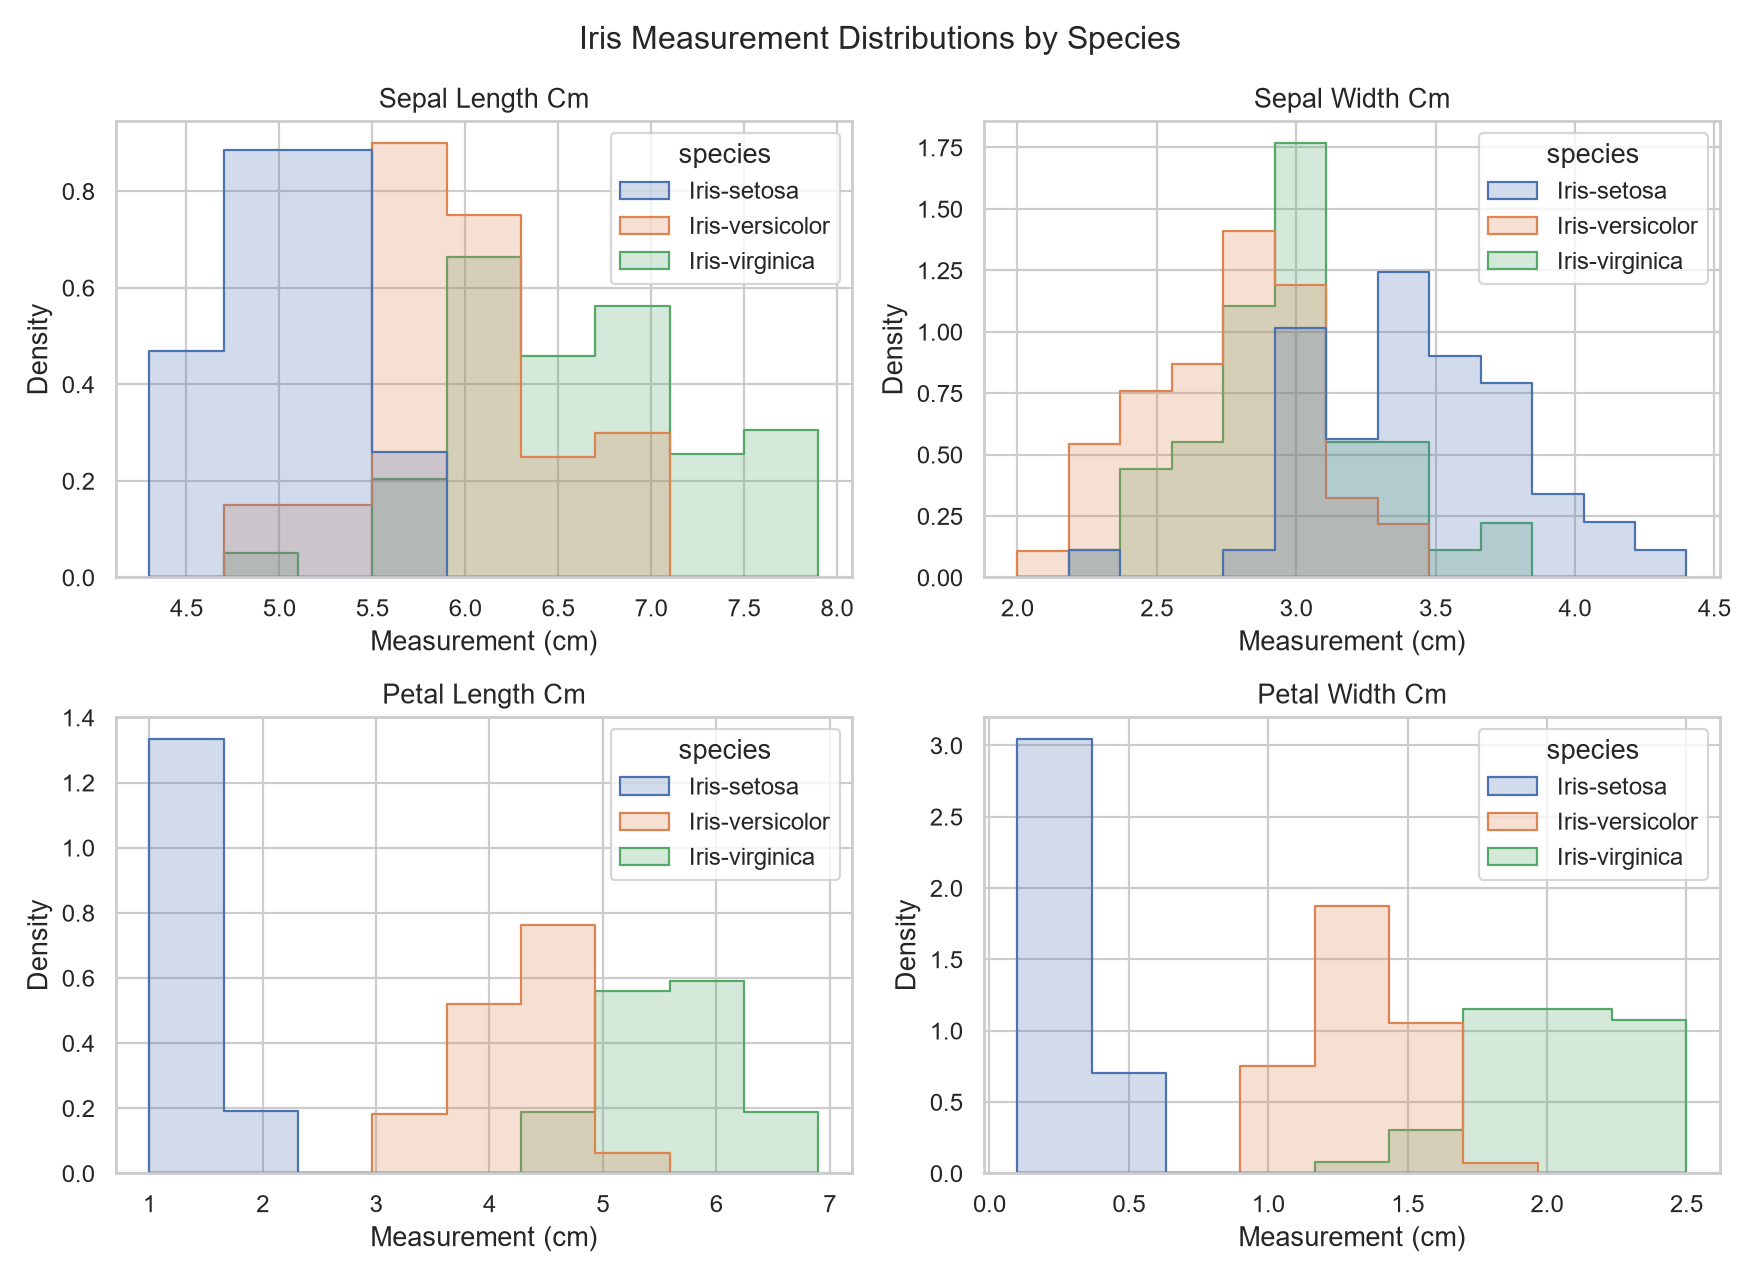

iris_scatter.png


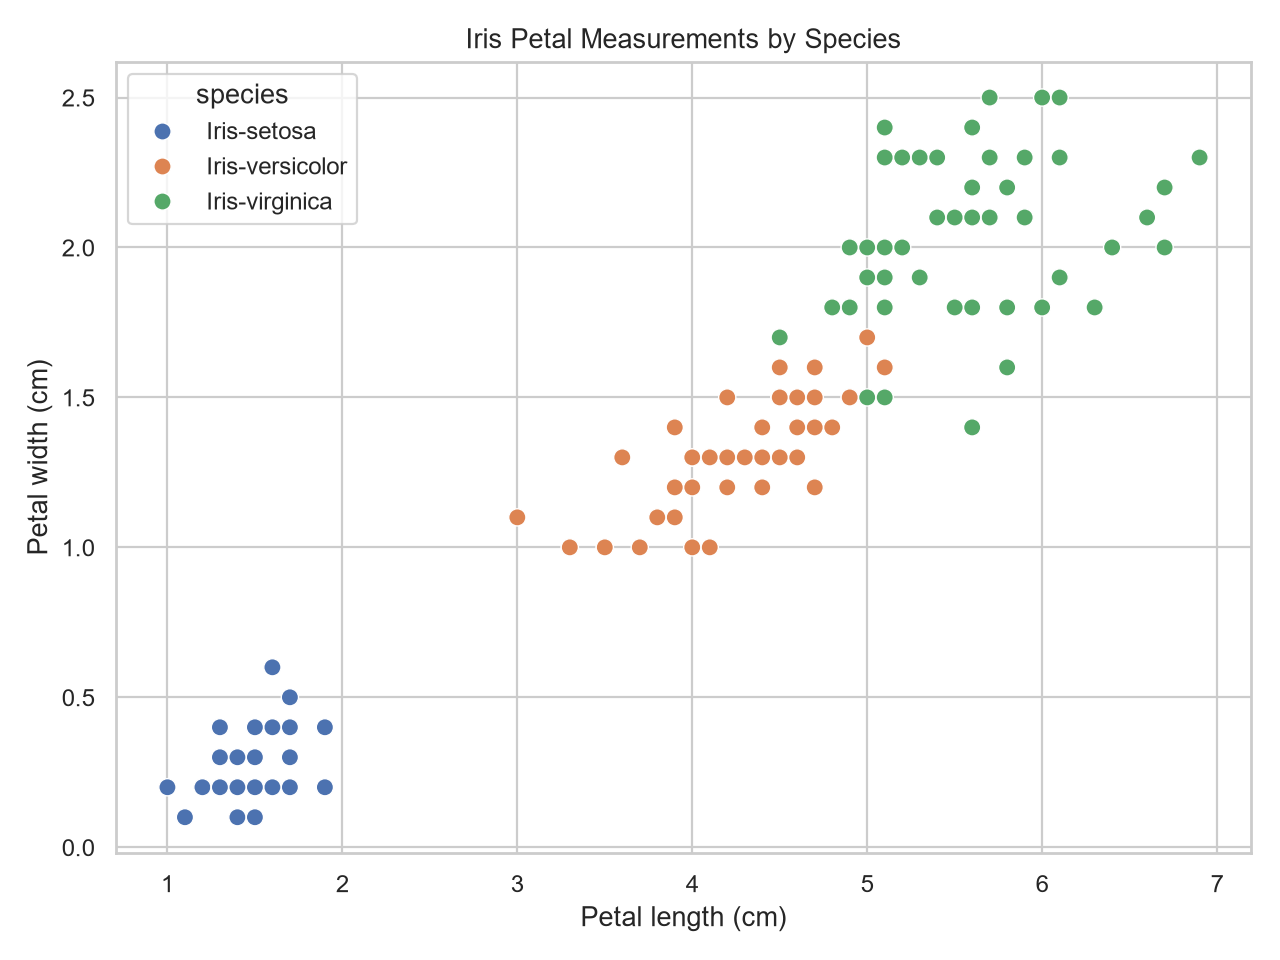

iris_boxplot.png


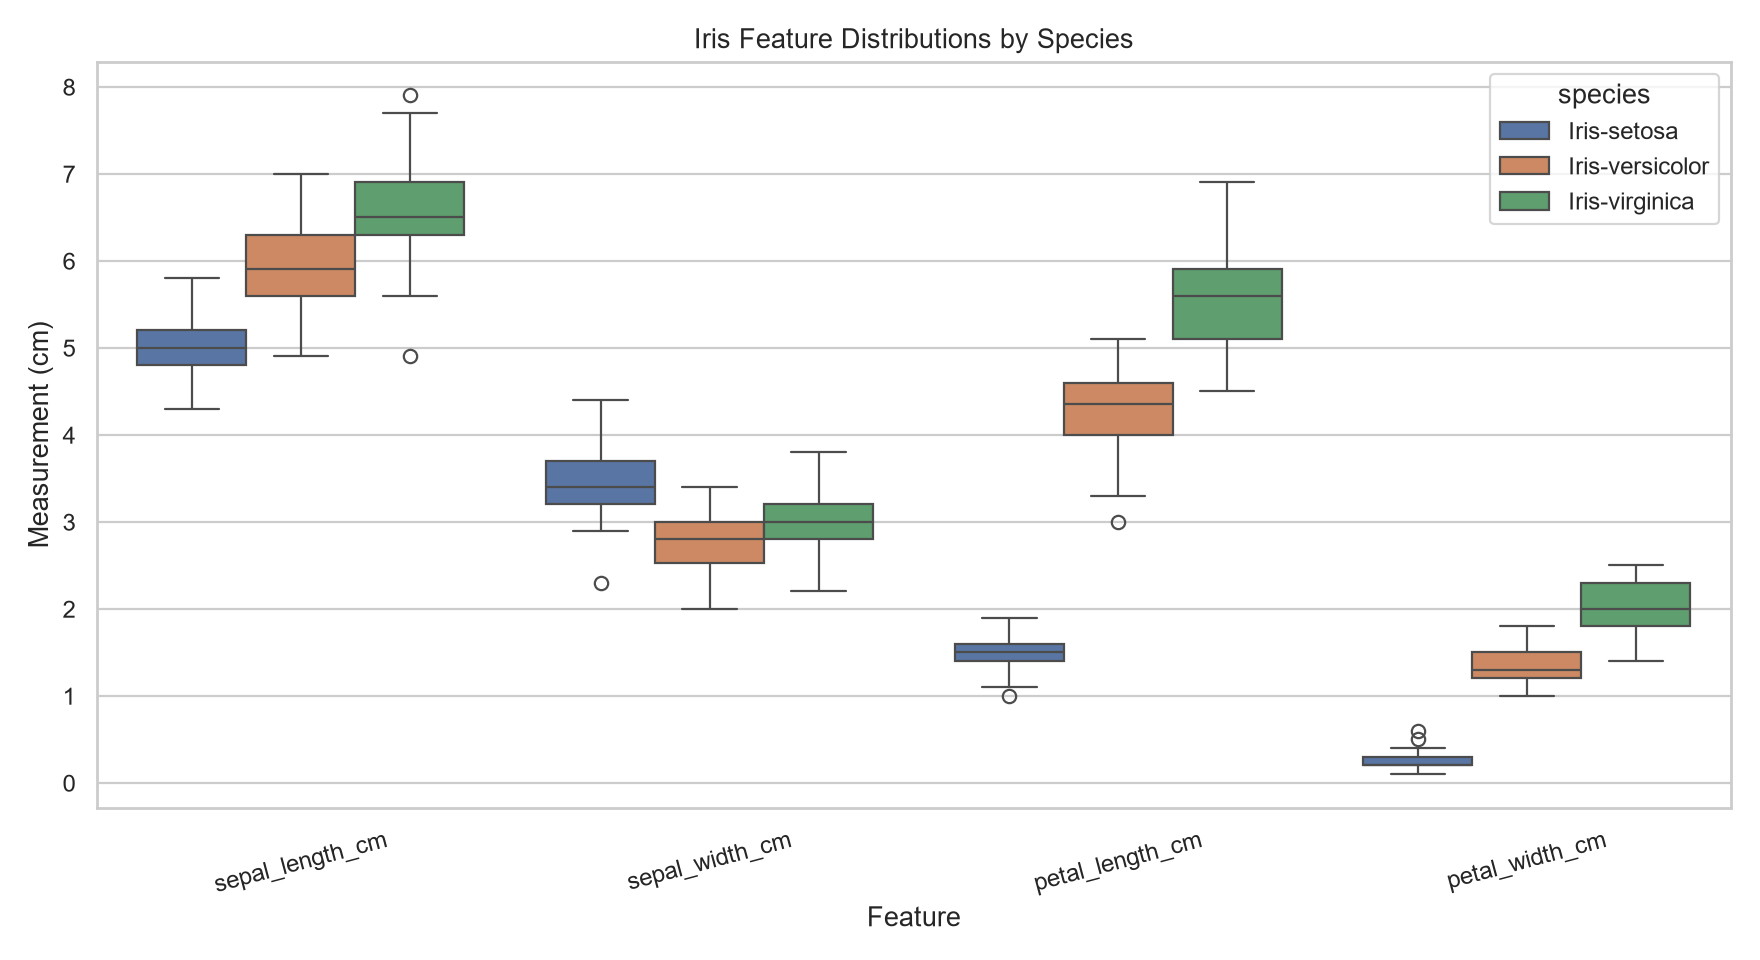

iris_heatmap.png


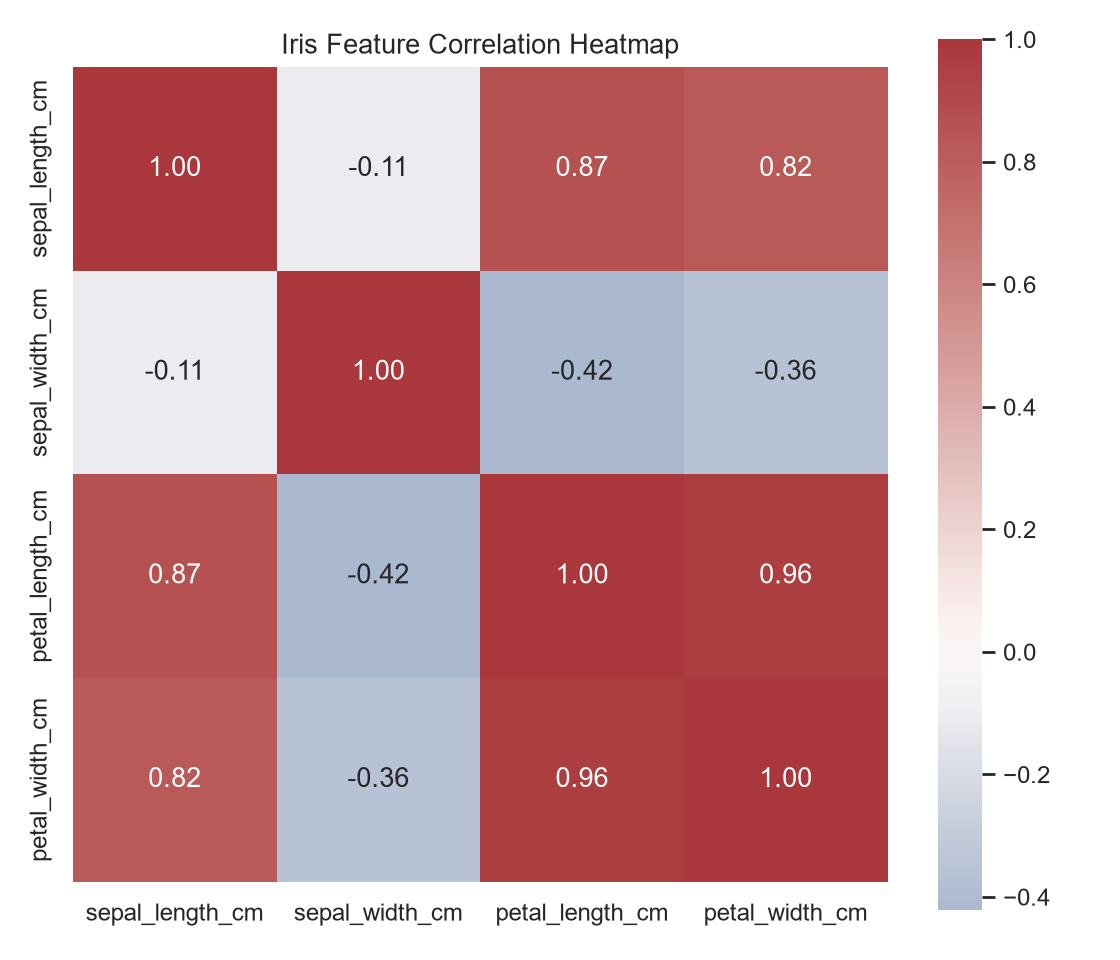

In [4]:
for filename in ['iris_histograms.png','iris_scatter.png','iris_boxplot.png','iris_heatmap.png']:
    print(filename)
    display(Image(filename=str(ROOT / 'images' / filename)))

## Observations, limitations, and conclusion
The original table has **150 rows**, no missing cells, and **3 exact duplicate rows**; the cleaned table has **147 rows** (48 setosa, 50 versicolor, 49 virginica). Mean petal length rises from **1.46 cm** for setosa to **4.26 cm** for versicolor and **5.56 cm** for virginica; mean petal width rises from **0.25 cm** to **1.33 cm** and **2.03 cm**. The petal scatter separates setosa clearly, while versicolor and virginica have some overlap. These describe this small, classic dataset and should not be generalized to all Iris populations. Correlation does not imply causation.